# Statistical mechanics and integration

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Boltzmann populations
One ground state and three degenerate excited states at energy ε. Plot versus βε and identify the entropy contribution.

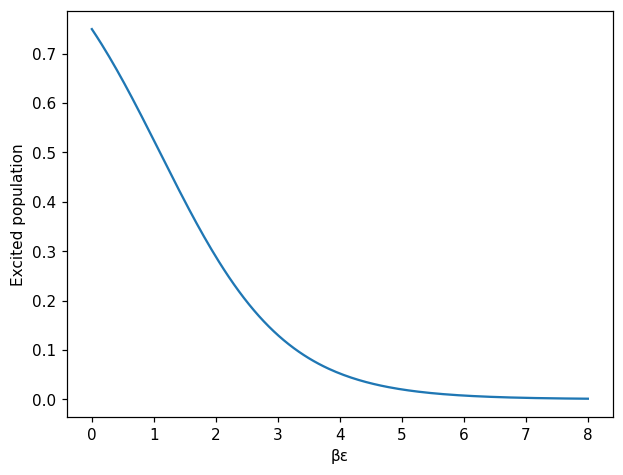

In [2]:
x=np.linspace(0,8,200)
p=3*np.exp(-x)/(1+3*np.exp(-x))
plt.plot(x,p); plt.xlabel('βε'); plt.ylabel('Excited population'); plt.show()
assert np.isclose(p[0],.75)

## Harmonic MC
Reduced units: kBT=k=1. Record rejections. The analytical variance is one; finite estimates fluctuate.

Sample mean, variance: -0.005565129390560643 1.0017063245366284


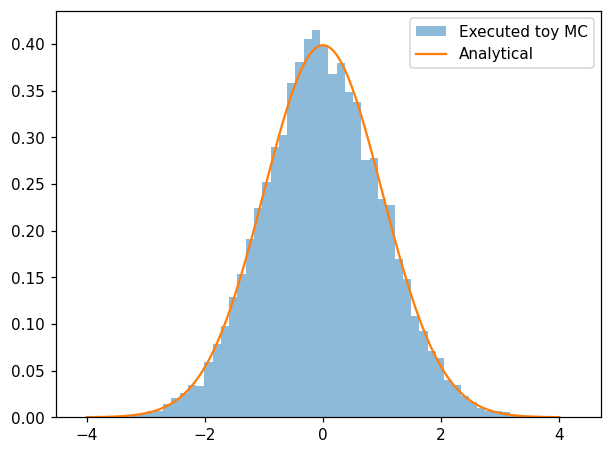

In [3]:
rng=np.random.default_rng(17)
q=0.; samples=[]
for i in range(40000):
    trial=q+rng.uniform(-2,2)
    if np.log(rng.random())<min(0.,-.5*(trial*trial-q*q)):q=trial
    if i>=2000:samples.append(q)
samples=np.array(samples)
print('Sample mean, variance:',samples.mean(),samples.var())
grid=np.linspace(-4,4,200)
plt.hist(samples,bins=60,density=True,alpha=.5,label='Executed toy MC')
plt.plot(grid,np.exp(-grid**2/2)/np.sqrt(2*np.pi),label='Analytical')
plt.legend();plt.show()

## Velocity Verlet stability
A harmonic oscillator has unit mass and frequency. Compare stable accuracy with instability; energy is x²/2+v²/2.

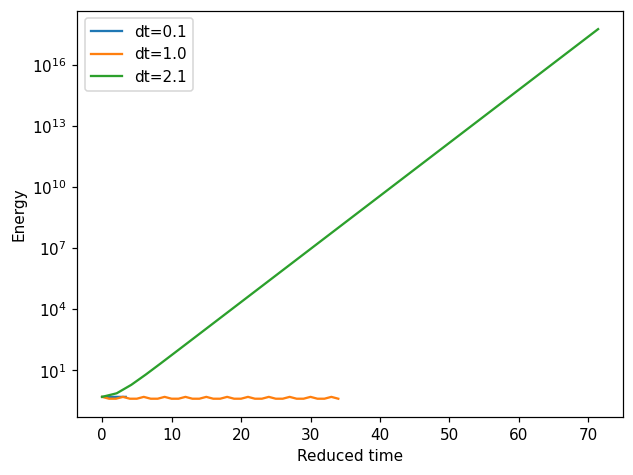

In [4]:
for dt in [.1,1.,2.1]:
    q,v=1.,0.; trace=[]
    for step in range(35):
        trace.append((step*dt,.5*(q*q+v*v)))
        v-=.5*dt*q; q+=dt*v; v-=.5*dt*q
    trace=np.array(trace)
    plt.semilogy(trace[:,0],trace[:,1],label=f'dt={dt}')
plt.xlabel('Reduced time');plt.ylabel('Energy');plt.legend();plt.show()

**Exercise:** repeat with equal physical observation duration and halve the smallest step. Explain why bounded energy alone does not guarantee the correct oscillator period.